In [1]:
# mamba activate spatiocore_spatial_env
import tifffile
import os
from spatialdata.models import Image2DModel
import spatialdata_io
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import numpy as np
from spatialdata.models import ShapesModel
import anndata
import scanpy as sc
from spatialdata import SpatialData
from spatialdata import polygon_query
from spatialdata import bounding_box_query
# from napari_spatialdata import Interactive
from spatialdata.models import TableModel
from spatialdata_plot.pl.utils import set_zero_in_cmap_to_transparent
from spatialdata import SpatialData
from napari.utils.colormaps import Colormap
from napari_spatialdata import Interactive
import spatialdata as sd
from scipy import ndimage as ndi
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl
import pickle

from spatialdata.transformations import (
    BaseTransformation,
    Identity,
    Sequence,
    align_elements_using_landmarks,
    get_transformation,
    set_transformation,
    Affine
)

In [2]:
import pickle
import sys


sys.path.insert(
    0,
    "/data/kanferg/Sptial_Omics/projects/NguyenLab/neuroblastoma"
)

from helper.utils import add_cluster_from_pickle
from helper.high_res_plot import PunchPlotter

In [3]:
pathad = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
andata = sc.read_h5ad(os.path.join(pathad, "adata_nb_processed_v1.h5ad"))

In [ ]:
annotation_colors = {
    "DISCARD": "#F2F2F2",

    # NB / tumor states: all gray for now
    "Adrenergic_Proliferating_NB": "#FF3B30",
    "Transitional_NB": "#00D1FF",
    "Adrenergic_StemLike_NB": "#39FF14",
    "Adrenergic_Cycling_NB": "#FF4FD8",
    "Adrenergic_MYCNHigh_Metabolic_NB": "#FFD60A",
    "Mesenchymal_NB": "#8E5CFF",

    # Non-NB compartments
    "Schwann_CAF": "#C49A6C",
    "M2_TAM": "#4292C6",
    "CD8_Cytotoxic_TCell_PartiallyExhausted": "#D62728",
    "MonocyteDerived_TissueResident_Macrophage": "#08519C",
    "Endothelial": "#29CF17",
    "Adrenocortical_Steroidogenic": "#F16913",
}

In [5]:
map_annotation = dict(zip(andata.obs['cell_id'], andata.obs["annotation_v1"]))

In [6]:
path_zarr = '/data/HiTIF/data/spatialomics/neuroblastoma/data/SCAF4480/PrimaryAnalysisOutput/SCAF4480_PA_xenium/nb_orig_label_v1.zarr'
sdata = sd.read_zarr(path_zarr)

version mismatch: detected: RasterFormatV02, requested: FormatV04


/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/vf/users/kanferg/conda_v1/envs/spatialdata_env/lib/python3.12/site-packages/zarr/creation.py:610: UserW

In [34]:
import importlib
import helper.high_res_plot as high_res_plot
importlib.reload(high_res_plot)
PunchPlotter = high_res_plot.PunchPlotter


sdata_obj = PunchPlotter(sdata = sdata,element_name = '21')

/vf/users/kanferg/conda_v1/envs/spatiocore_spatial_env/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


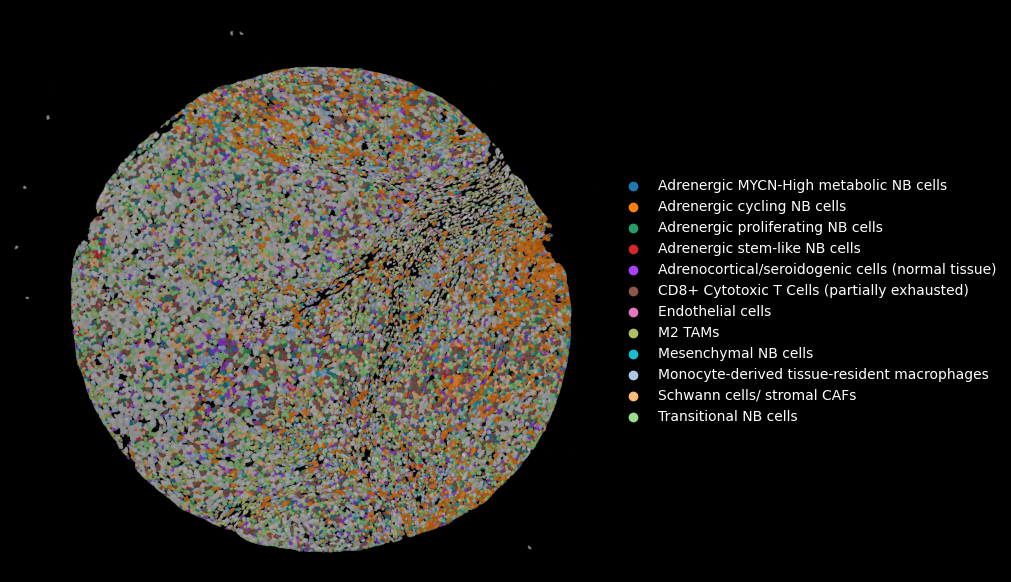

In [35]:
sdata_obj.plot_punch(
    colname="annotation_v1",
    colname_map=map_annotation,
    palette=annotation_colors,
)

## Phase 1 prototype: CAR high-resolution punch panels

The cells below keep the same SpatialData rendering path as the single-punch example. Each punch is cropped with `PunchPlotter`, rendered as DAPI + segmented labels, and then assembled into one shared-legend panel for NB and Non-NB annotations separately.


In [ ]:
from pathlib import Path
import tempfile

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

import importlib
import helper.high_res_plot as high_res_plot
importlib.reload(high_res_plot)
PunchPlotter = high_res_plot.PunchPlotter

project_dir = Path("/data/kanferg/Sptial_Omics/projects/NguyenLab/neuroblastoma")

nb_annotations = [
    "Adrenergic_Proliferating_NB",
    "Transitional_NB",
    "Adrenergic_StemLike_NB",
    "Adrenergic_Cycling_NB",
    "Adrenergic_MYCNHigh_Metabolic_NB",
    "Mesenchymal_NB",
]

non_nb_annotations = [
    "Schwann_CAF",
    "M2_TAM",
    "CD8_Cytotoxic_TCell_PartiallyExhausted",
    "MonocyteDerived_TissueResident_Macrophage",
    "Endothelial",
    "Adrenocortical_Steroidogenic",
]

nb_palette = {label: annotation_colors[label] for label in nb_annotations}
non_nb_palette = {label: annotation_colors[label] for label in non_nb_annotations}

sample_table = pd.read_csv(project_dir / "data_in/05082026_Sample_punch_id.csv")
sample_table["Condition_clean"] = sample_table["Condition"].replace({
    "IL-15.CAR": "IL15",
    "IL-21.CAR": "IL21",
    "IL-15.IL-21.CAR": "Both",
})

punch_table = sample_table.dropna(subset=["punch_id"]).copy()
punch_table["punch_id"] = punch_table["punch_id"].astype(str).str.split(",")
punch_table = punch_table.explode("punch_id")
punch_table["punch_id"] = punch_table["punch_id"].str.strip()
punch_table = punch_table[punch_table["punch_id"].isin(list(sdata.shapes.keys()))].copy()

car_punches = punch_table.loc[punch_table["Condition_clean"] == "CAR", "punch_id"].tolist()
car_punches_small = car_punches[:2]

punch_titles = {}
for _, row in punch_table.iterrows():
    title_bits = [f"Punch {row['punch_id']}"]
    if pd.notna(row.get("Type")):
        title_bits.append(str(row["Type"]))
    if pd.notna(row.get("Ear tag")):
        title_bits.append(f"Mouse {row['Ear tag']}")
    punch_titles[row["punch_id"]] = " | ".join(title_bits)

car_punches_small


In [ ]:
def make_highres_panel(punches, active_labels, palette, panel_title, save_file=None):
    n_punches = len(punches)
    ncols = min(4, n_punches)
    nrows = int(np.ceil(n_punches / ncols))

    with tempfile.TemporaryDirectory() as tmpdir:
        image_paths = []
        for punch_id in punches:
            image_path = Path(tmpdir) / f"{panel_title}_{punch_id}.png"
            sdata_obj = PunchPlotter(
                sdata=sdata,
                element_name=str(punch_id),
                legend_loc=None,
                dpi=300,
            )
            ax = sdata_obj.plot_punch(
                colname="annotation_v1",
                colname_map=map_annotation,
                palette=palette,
                active_labels=active_labels,
                figsize=(6, 6),
                title=" ",
                legend_loc=None,
                show=False,
                save_path=image_path,
                dpi=300,
            )
            plt.close(ax.figure)
            image_paths.append(image_path)

        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(4.0 * ncols, 4.4 * nrows),
            dpi=300,
            squeeze=False,
        )
        axes_flat = axes.ravel()

        for ax, punch_id, image_path in zip(axes_flat, punches, image_paths):
            ax.imshow(mpimg.imread(image_path))
            ax.set_title(punch_titles.get(str(punch_id), f"Punch {punch_id}"), fontsize=9, pad=4)
            ax.set_axis_off()

        for ax in axes_flat[len(punches):]:
            ax.set_axis_off()

        handles = [Patch(facecolor=palette[label], edgecolor="none", label=label) for label in active_labels]
        legend_ncol = 2 if len(active_labels) <= 6 else 3
        fig.legend(
            handles=handles,
            loc="lower center",
            bbox_to_anchor=(0.5, -0.02),
            ncol=legend_ncol,
            frameon=False,
            fontsize=8,
        )
        fig.suptitle(panel_title, fontsize=12, y=0.995)
        fig.subplots_adjust(left=0.02, right=0.98, top=0.91, bottom=0.22, wspace=0.04, hspace=0.12)

        if save_file is not None:
            fig.savefig(save_file, dpi=300, bbox_inches="tight")

    return fig


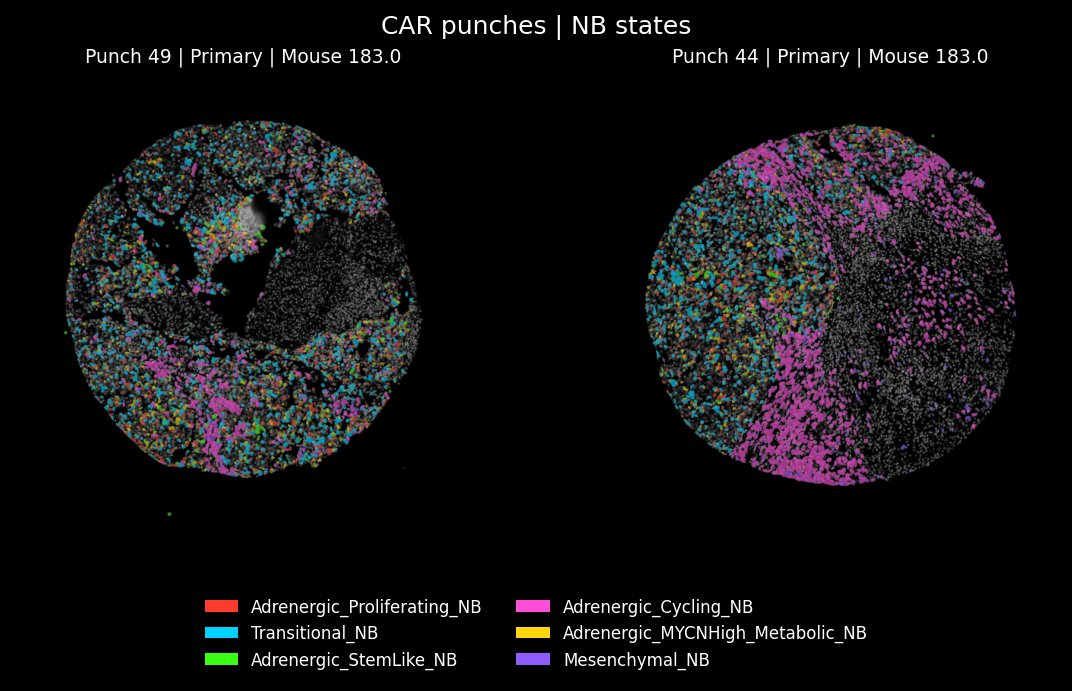

In [1]:
fig_nb_car = make_highres_panel(
    punches=car_punches_small,
    active_labels=nb_annotations,
    palette=nb_palette,
    panel_title="CAR punches | NB states",
)
plt.show()


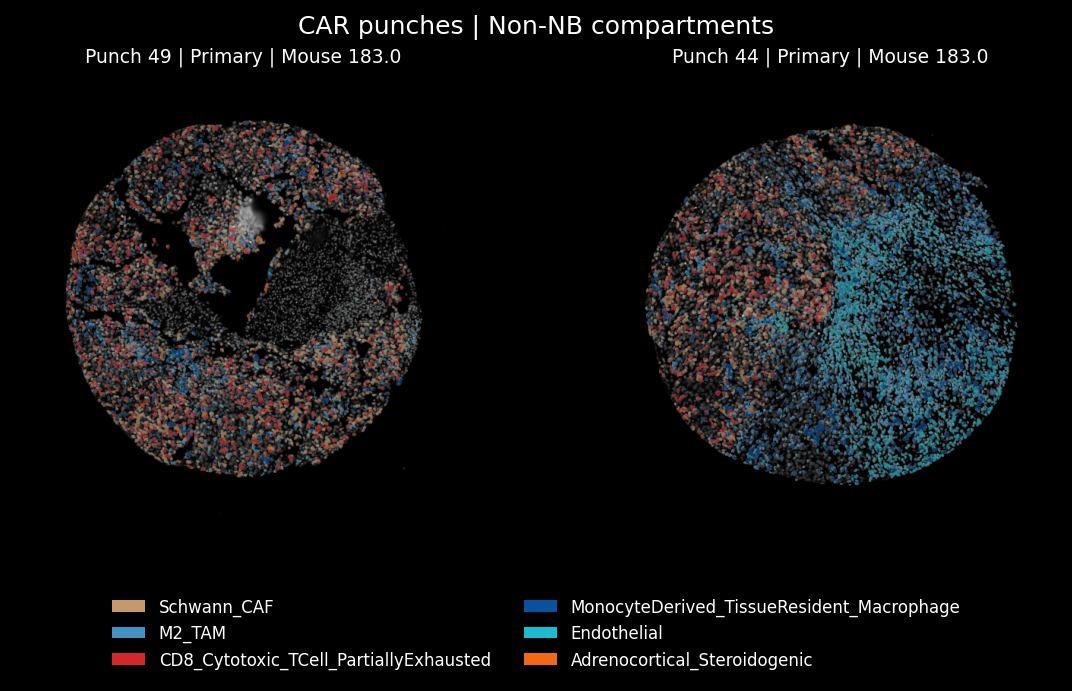

In [1]:
fig_non_nb_car = make_highres_panel(
    punches=car_punches_small,
    active_labels=non_nb_annotations,
    palette=non_nb_palette,
    panel_title="CAR punches | Non-NB compartments",
)
plt.show()
